# 05 — Diagnostics and ablations

This notebook answers two rounds of review questions about *why* the Phase 2 strategy behaves the way it does.

| # | Question | Section |
|---|---|---|
| Q9 / Q3 | Mean P&L of trades that exit by reversion vs by the clock, and what predicts the split | 1 |
| Q1 | How much of the 60-bar z-window is from today when a trade opens? | 2 |
| Q2 | When during the day do entries happen, and what is the signal reacting to? | 3 |
| Q4 | Standard error of the gross Sharpe ratio | 4 |
| Q5 | Window experiment: (a) as-is, (b) reset at the open, (c) wait for a full window. Predictions were pre-registered in `analysis/q5_predictions.md` | 5 |
| Q6 | Intraday seasonality of spread volatility. Is resetting the window enough? | 6 |
| Q7 | Ornstein-Uhlenbeck time to revert; exits at \|z\| ≤ 0.5 and a one-half-life time stop | 7 |
| Q8 | Entry rule: only enter if at least k half-lives remain in the session | 8 |

All runs use the same cached data, betas, thresholds and NSE cost model as notebooks 02–04 (trading period after a 15-day formation window; 44 trading days).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter

import backtest_report as br
import experiments as ex
import strategy as strat
from data_pipeline import load_universe

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
%matplotlib inline

FIG = Path.cwd().parent / "analysis" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
C0, C1, C2, C3 = br.SERIES_COLORS
EOD_MIN = 15 * 60 + 5 - (9 * 60 + 15)          # minutes from 09:15 to the 15:05 flatten
PAIRS = ["HDFCBANK/ICICIBANK", "TCS/INFY", "SBIN/BANKBARODA"]
universe = load_universe()

In [2]:
# Baseline (variant a) for every pair, with per-trade context columns
base = {}
for pair in PAIRS:
    px = universe[pair]
    sig, g, n = ex.run_pair(px)
    t = g.trades.copy()
    t["net_pnl"] = n.trades["net_pnl"].values
    t["pair"] = pair
    t["bars_into_day"] = sig.loc[t["signal_time"], "bars_into_day"].values
    t["today_bars_in_window"] = sig.loc[t["signal_time"], "today_bars_in_window"].values
    t["bars_left"] = (EOD_MIN - ex.minutes_after_open(t["signal_time"])) / 5   # clock-based, as in the rule
    base[pair] = dict(sig=sig, gross=g, net=n, trades=t, hl=ex.formation_half_life(px))
T = pd.concat([b["trades"] for b in base.values()])
pd.Series({p: round(b["hl"], 1) for p, b in base.items()}, name="formation half-life (bars)").to_frame()

,formation half-life (bars)
HDFCBANK/ICICIBANK,133.5
TCS/INFY,328.3
SBIN/BANKBARODA,46.0


## 1. Exit-reason split (Q9) and what predicts it (Q3)

`signal` = z reverted to the exit band. `eod` = closed by the 15:05 flatten.

In [3]:
q9 = pd.concat({p: ex.exit_reason_table(b["gross"], b["net"]) for p, b in base.items()})
pooled = T.groupby("exit_reason").agg(trades=("gross_pnl", "size"), mean_gross_pnl=("gross_pnl", "mean"),
                                       mean_net_pnl=("net_pnl", "mean"), mean_bars_held=("bars_held", "mean"))
q9 = pd.concat([q9, pd.concat({"All 3 pairs": pooled})])
q9.round(0)

trades  mean_gross_pnl  mean_net_pnl  mean_bars_held
                   exit_reason                                                      
HDFCBANK/ICICIBANK eod              22         -1495.0       -2341.0            32.0
                   signal           30          1010.0         164.0            37.0
TCS/INFY           eod              20         -2351.0       -3195.0            42.0
                   signal           32           898.0          53.0            30.0
SBIN/BANKBARODA    eod              26         -1029.0       -1875.0            31.0
                   signal           33          1201.0         355.0            29.0
All 3 pairs        eod              68         -1569.0       -2414.0            35.0
                   signal           95          1039.0         193.0            32.0

Trades that revert make money even after costs; trades the clock closes lose about ₹1,000–2,400 each before costs. That's the symptom. The cause is how much session is left when the trade opens, measured in units of the Phase 1 half-life:

In [4]:
sb = base["SBIN/BANKBARODA"]
t = sb["trades"].assign(enough_time=lambda d: np.where(d["bars_left"] > sb["hl"], "more than 1 half-life left",
                                                          "less than 1 half-life left"))
t.groupby("enough_time").agg(trades=("gross_pnl", "size"),
                             reverted=("exit_reason", lambda x: (x == "signal").mean()),
                             mean_gross_pnl=("gross_pnl", "mean"), mean_bars_left=("bars_left", "mean")).round(2)

,trades,reverted,mean_gross_pnl,mean_bars_left
enough_time,,,,
less than 1 half-life left,21,0.14,53.07,19.57
more than 1 half-life left,38,0.79,309.47,66.84


The half-life (46 bars on SBIN/BANKBARODA) splits the trades almost perfectly into "mostly reverts" and "almost never reverts". Section 8 turns this into an entry rule.

## 2. How much of the z-window is from today at entry? (Q1)

Measured at the **signal bar** (the fill is one bar later). `today_bars_in_window` = min(bars printed today, 60).

In [5]:
def window_stats(d):
    w = d["today_bars_in_window"]
    return pd.Series({"trades": len(d), "median bars from today": w.median(), "exactly 1 (09:15 bar)": (w == 1).mean(),
                      "12 or fewer (first hour)": (w <= 12).mean(), "fewer than 30": (w < 30).mean(), "full 60": (w == 60).mean()})
q1 = pd.concat([T.groupby("pair").apply(window_stats), window_stats(T).to_frame("All 3 pairs").T])
q1.style.format({c: "{:.0%}" for c in q1.columns if c not in ("trades", "median bars from today")} | {"trades": "{:.0f}", "median bars from today": "{:.0f}"})

,trades,median bars from today,exactly 1 (09:15 bar),12 or fewer (first hour),fewer than 30,full 60
HDFCBANK/ICICIBANK,52,2,42%,65%,71%,15%
SBIN/BANKBARODA,59,6,29%,58%,69%,12%
TCS/INFY,52,4,29%,63%,71%,12%
All 3 pairs,163,4,33%,62%,71%,13%


The typical trade compares this morning's spread with a mean and standard deviation built almost entirely from **yesterday afternoon**.

## 3. Entries by time of day (Q2)

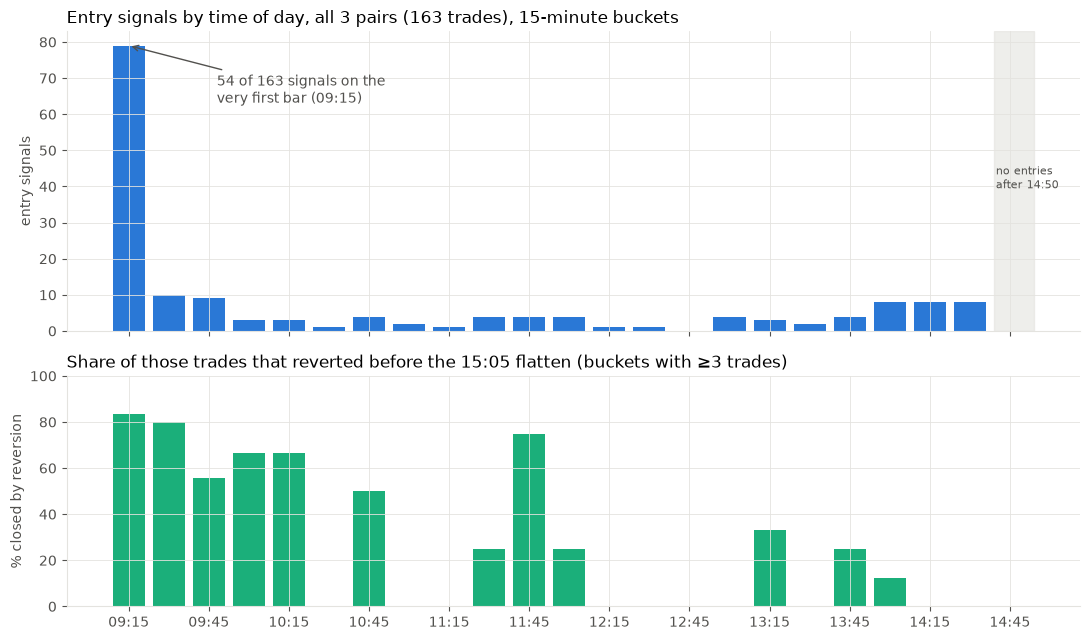

In [6]:
m = ex.minutes_after_open(T["signal_time"])
b15 = m // 15
labels = [f"{(555 + 15 * i) // 60:02d}:{(555 + 15 * i) % 60:02d}" for i in range(23)]
cnt = pd.Series(b15).value_counts().reindex(range(23), fill_value=0)
rev = pd.Series((T["exit_reason"] == "signal").values).groupby(b15).mean().reindex(range(23))
n_b = pd.Series(b15).value_counts().reindex(range(23), fill_value=0)

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
ax[0].bar(range(23), cnt.values, color=C0, width=0.8)
first = (T["bars_into_day"] == 0).sum()
ax[0].annotate(f"{first} of {len(T)} signals on the\nvery first bar (09:15)", xy=(0, cnt.iloc[0]),
               xytext=(2.2, cnt.iloc[0] * 0.8), color=br.TEXT_COLOR, arrowprops=dict(arrowstyle="->", color=br.TEXT_COLOR))
ax[0].axvspan(21.6, 22.6, color=br.GRID_COLOR, alpha=0.6)
ax[0].text(21.65, cnt.max() * 0.5, "no entries\nafter 14:50", fontsize=8, color=br.TEXT_COLOR)
ax[0].set_ylabel("entry signals")
ax[0].set_title(f"Entry signals by time of day, all 3 pairs ({len(T)} trades), 15-minute buckets", loc="left")
ok = n_b.values >= 3
ax[1].bar(np.arange(23)[ok], rev.values[ok] * 100, color=C2, width=0.8)
ax[1].set_ylabel("% closed by reversion"); ax[1].set_ylim(0, 100)
ax[1].set_title("Share of those trades that reverted before the 15:05 flatten (buckets with ≥3 trades)", loc="left")
ax[1].set_xticks(range(0, 23, 2)); ax[1].set_xticklabels(labels[::2])
fig.tight_layout(); fig.savefig(FIG / "entry_timing.png", dpi=130); plt.show()

In [7]:
grp = pd.cut(T["bars_into_day"], [-1, 0, 11, 40, 80],
             labels=["09:15 bar (1 of 60 from today)", "09:20-10:10", "10:15-12:40", "12:45-14:45"])
T.groupby(grp, observed=True).agg(trades=("gross_pnl", "size"), reverted=("exit_reason", lambda x: (x == "signal").mean()),
                                  mean_gross=("gross_pnl", "mean"), mean_net=("net_pnl", "mean")).round(2)

,trades,reverted,mean_gross,mean_net
bars_into_day,,,,
09:15 bar (1 of 60 from today),54,0.85,195.08,-649.92
09:20-10:10,47,0.74,-347.95,-1193.56
10:15-12:40,24,0.46,-151.06,-996.50
12:45-14:45,38,0.08,38.11,-808.20


In [8]:
# How much of each reversion was the rolling mean moving toward the spread, rather than the spread moving back?
# gap at signal = spread - mean; it closes by (d_spread - d_mean). Share due to the mean = d_mean / gap.
sig = base["SBIN/BANKBARODA"]["sig"]
rev_t = base["SBIN/BANKBARODA"]["trades"].query("exit_reason == 'signal'")
shares = []
for _, tr in rev_t.iterrows():
    a = sig.loc[tr["signal_time"]]
    b = sig.iloc[sig.index.get_loc(tr["exit_time"]) - 1]          # the bar whose z triggered the exit
    gap = a["spread"] - a["spread_mean"]
    shares.append({"open bar": tr["bars_into_day"] == 0, "share closed by the mean moving": (b["spread_mean"] - a["spread_mean"]) / gap})
pd.DataFrame(shares).groupby("open bar")["share closed by the mean moving"].median().round(2).to_frame("median")

,median
open bar,
False,0.35
True,0.58


**Not flat.** Half the signals fire in the first 15 minutes, a third on the first bar. Three mechanisms:

1. **Overnight gap.** At 09:15 the spread jumps by the overnight relative move, which is 5–9× a normal 5-minute change (section 6), and is compared with a window of 59 bars from yesterday. z measures the gap, not intraday mispricing.
2. **Small denominator.** Yesterday's afternoon bars are the calmest of the day (section 6), so the rolling std is small exactly when the numerator is large.
3. **Part of the "reversion" is mechanical.** As today's bars replace yesterday's in the window, the rolling mean moves toward the new level. For SBIN/BANKBARODA, a median 58% of the gap closed on open-bar trades came from the mean catching up rather than the spread moving back (35% for other trades).

The smaller afternoon cluster (13:45–14:45) is the opposite failure: ordinary deviations, but too little session left, so they almost never revert (section 1).

## 4. Standard error of the gross Sharpe ratio (Q4)

In [9]:
g = base["SBIN/BANKBARODA"]["gross"]
r = br.daily_returns(g.equity, g.capital)
rf = (1 + br.RISK_FREE_RATE_ANNUAL) ** (1 / 252) - 1
x = (r - rf).values
n_days = len(x)
sr_d = x.mean() / r.std()
sr = sr_d * np.sqrt(252)
se_lo = np.sqrt((1 + sr_d ** 2 / 2) / n_days) * np.sqrt(252)      # Lo (2002), iid returns
rng = np.random.default_rng(0)
boot = np.array([(y := x[rng.integers(0, n_days, n_days)]).mean() / y.std(ddof=1) * np.sqrt(252) for _ in range(20_000)])
pd.Series({"trading days": n_days, "gross Sharpe": sr, "SE (Lo 2002)": se_lo, "SE (bootstrap)": boot.std(),
           "95% CI low": np.percentile(boot, 2.5), "95% CI high": np.percentile(boot, 97.5),
           "P(Sharpe <= 0)": (boot <= 0).mean(), "t-stat of mean daily excess": x.mean() / (x.std(ddof=1) / np.sqrt(n_days)),
           "days for SE = 0.5": 252 * (1 + sr ** 2 / 504) / 0.25}).round(2).to_frame("value")

,value
trading days,44.00
gross Sharpe,0.26
SE (Lo 2002),2.39
SE (bootstrap),2.50
95% CI low,-4.16
95% CI high,5.69
P(Sharpe <= 0),0.45
t-stat of mean daily excess,0.11
days for SE = 0.5,1008.13


A Sharpe of 0.26 with a standard error of ~2.4 is indistinguishable from zero (or from ±3). It is also selected (best of three pairs) and gross of costs. **The point estimate is not defensible.** Every Sharpe comparison below should be read against this standard error: differences smaller than ~2.4 are noise.

## 5. Window experiment (Q5)

Same data, betas, thresholds and costs; only the treatment of the overnight gap changes.

- **(a) as-is**: rolling 60-bar window across days.
- **(b) reset at open**: window uses today's bars only; z exists from the 20th bar (10:50).
- **(c) wait for full window**: rolling window as in (a), but no entries until all 60 bars are from today (from 14:10).

Predictions were committed to `analysis/q5_predictions.md` before this ran.

In [10]:
runs = {}
rows = []
for pair in PAIRS:
    for name, kw in ex.WINDOW_VARIANTS.items():
        skw, bkw = ex.split_kw(kw)
        sig, gr, ne = ex.run_pair(universe[pair], skw, bkw)
        runs[(pair, name)] = (sig, gr, ne)
        rows.append({"pair": pair, "variant": name, **ex.summarise(gr, ne)})
q5 = pd.DataFrame(rows).set_index(["pair", "variant"])
q5.style.format({"Gross return": "{:.2%}", "Net return": "{:.2%}", "Gross Sharpe": "{:.2f}", "Net Sharpe": "{:.2f}",
                 "Entries in first 30 min": "{:.0%}", "Exits by reversion": "{:.0%}", "Avg gross P&L / trade (INR)": "{:,.0f}"})

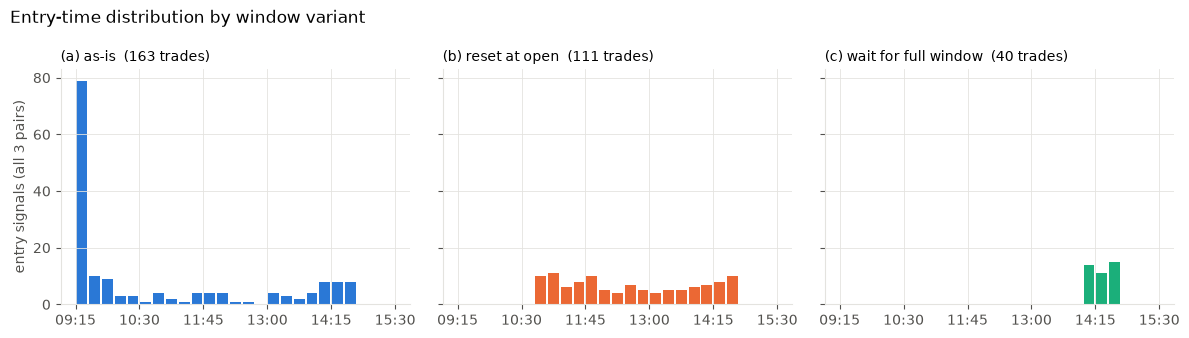

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
edges = np.arange(0, 375 + 15, 15)
for ax, (name, color) in zip(axes, zip(ex.WINDOW_VARIANTS, [C0, C1, C2])):
    mm = np.concatenate([ex.entry_minutes(runs[(p, name)][1].trades) for p in PAIRS])
    ax.hist(mm, bins=edges, color=color, rwidth=0.85)
    ax.set_title(f"{name}  ({len(mm)} trades)", loc="left", fontsize=10)
    ax.set_xticks([0, 75, 150, 225, 300, 375]); ax.set_xticklabels(["09:15", "10:30", "11:45", "13:00", "14:15", "15:30"])
axes[0].set_ylabel("entry signals (all 3 pairs)")
fig.suptitle("Entry-time distribution by window variant", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "q5_entry_distribution.png", dpi=130); plt.show()

### Checking the two "would surprise me" cases

In [12]:
# (b): are the first bars after the 20-bar warm-up a losing cluster?
xs = []
for p in PAIRS:
    sig, gr, ne = runs[(p, "(b) reset at open")]
    xs.append(pd.DataFrame({"bars_into_day": sig.loc[gr.trades["signal_time"], "bars_into_day"].values,
                            "gross": gr.trades["gross_pnl"].values, "net": ne.trades["net_pnl"].values}))
X = pd.concat(xs)
X["when"] = pd.cut(X["bars_into_day"], [18, 22, 35, 80], labels=["first 3 allowed bars (10:50-11:00)", "11:05-12:10", "12:15+"])
X.groupby("when", observed=True).agg(trades=("gross", "size"), mean_gross=("gross", "mean"), mean_net=("net", "mean")).round(0)

,trades,mean_gross,mean_net
when,,,
first 3 allowed bars (10:50-11:00),17,-634.0,-1480.0
11:05-12:10,33,-120.0,-966.0
12:15+,61,-201.0,-1047.0


In [13]:
# (c): is the positive gross return on SBIN/BANKBARODA real?
rows = []
for p in PAIRS + ["All 3 pairs"]:
    x = (np.concatenate([runs[(q, "(c) wait for full window")][1].trades["gross_pnl"].values for q in PAIRS])
         if p == "All 3 pairs" else runs[(p, "(c) wait for full window")][1].trades["gross_pnl"].values)
    rows.append({"pair": p, "trades": len(x), "mean gross P&L": x.mean(),
                 "t-stat": x.mean() / (x.std(ddof=1) / np.sqrt(len(x))),
                 "largest trade / total": x.max() / x.sum() if x.sum() > 0 else np.nan})
pd.DataFrame(rows).set_index("pair").round(2)

,trades,mean gross P&L,t-stat,largest trade / total
pair,,,,
HDFCBANK/ICICIBANK,15,-408.01,-0.62,NaN
TCS/INFY,12,118.87,0.12,3.94
SBIN/BANKBARODA,13,1295.54,1.72,0.51
All 3 pairs,40,303.71,0.67,0.71


### Predictions vs results (SBIN/BANKBARODA)

| Variant | Prediction | Result | Right? |
|---|---|---|---|
| (b) trades | fewer, 30–45 | 34 | ✓ |
| (b) entry times | mostly 10:55–12:30 | median 12:45; 10th–90th pct 10:50–14:20, spread across the day | ✗ later and wider than predicted |
| (b) gross return | lower, near zero or slightly negative | −0.9% (from +1.3%) | ✓ |
| (b) net return | about the same, −3% to −5% | −3.8% (from −3.7%) | ✓ |
| (b) gross Sharpe | lower, not meaningful | −3.3 (from 0.26), about one standard error of the difference | ✓ |
| (b) mechanism | more end-of-day exits | reversion exits fell from 56% to 26% | ✓ |
| (c) trades | far fewer, 8–15 | 13 | ✓ |
| (c) entry times | all 14:10–14:50 | 14:10–14:40 | ✓ |
| (c) gross return | lower, close to zero | **+1.7%** (higher than (a)) | ✗ |
| (c) net return | higher, −1% to −1.5% | **+0.6%** | direction ✓, size ✗ |
| (c) Sharpe | gross lower, net less negative | gross 1.35 (higher), net −1.28 (less negative) | half ✓ |
| (c) mechanism | nearly all exit on the clock; gain purely from trading less | 92% clock exits ✓; but gross also rose, so not purely from trading less ✗ | half ✓ |

**Score: 7 of 12 right, 3 half right, 2 wrong.** Both "would surprise me" cases happened, partly:

- **(b) warm-up cluster.** The first three allowed bars (10:50–11:00) are over-represented, 17 of 111 trades pooled vs ~7 expected if entries were spread evenly, and they are the worst-performing group (−₹634 gross, −₹1,480 net on average). That supports the small-sample artifact: a 20-bar std underestimates the true spread volatility, which in the morning is still elevated (section 6).
- **(c) positive gross.** Real on SBIN/BANKBARODA (+₹1,296/trade) but not robust: one trade is 51% of the total, t = 1.72, and the other two pairs show −₹408 and +₹119 (pooled t = 0.67). I read it as noise, not a late-afternoon effect, but it is the one result worth re-testing on more data.

**Overall:** neither (b) nor (c) fixes the strategy. (b) removes the overnight-gap artifact and replaces it with worse-timed trades; (c) trades so little that costs shrink, which flatters net return without showing a better signal.

## 6. Intraday seasonality of spread volatility (Q6)

Average |Δspread| per 5-minute bar, in bps of A's price, using each day's own β. Each pair is normalized by its own average intraday |Δspread| so the three can be pooled. The overnight change (first bar) is reported separately.

In [14]:
profiles, overnight = [], {}
for p in PAIRS:
    d = ex.spread_change_by_bar(base[p]["sig"])
    intra = d[~d["overnight"]]
    scale = intra["abs_change_bps"].mean()
    overnight[p] = d.loc[d["overnight"], "abs_change_bps"].mean() / scale
    profiles.append((intra.groupby("slot")["abs_change_bps"].mean() / scale).rename(p))
prof = pd.concat(profiles, axis=1)
prof["pooled"] = prof.mean(axis=1)
hour = (prof.index * 5 + 555) // 60
display(pd.Series(overnight, name="overnight |change| / avg intraday |change|").round(1).to_frame())
prof["pooled"].groupby(hour).mean().round(2).to_frame("avg |Δspread| relative to the day's average, by hour").T

,overnight |change| / avg intraday |change|
HDFCBANK/ICICIBANK,8.4
TCS/INFY,9.0
SBIN/BANKBARODA,5.0


slot,9,10,11,12,13,14,15
"avg |Δspread| relative to the day's average, by hour",1.51,0.98,0.93,0.82,0.77,0.89,1.97


In [15]:
# z exceedance by hour: real data (a) and (b), and a constant-volatility OU simulation with the same windows
def exceed_by_hour(sig_list):
    e = pd.concat([ex.z_exceedance_by_slot(s) for s in sig_list], axis=1).mean(axis=1)
    return e.groupby((e.index * 5 + 555) // 60).mean()

real_a = exceed_by_hour([runs[(p, "(a) as-is")][0] for p in PAIRS])
real_b = exceed_by_hour([runs[(p, "(b) reset at open")][0] for p in PAIRS])

# Simulation: OU spread, half-life 46 bars, constant volatility, 75-bar days, 3,000 days. No seasonality.
rng = np.random.default_rng(1)
phi = 0.5 ** (1 / 46)
s = pd.Series(lfilter([np.sqrt(1 - phi ** 2)], [1, -phi], rng.standard_normal(3000 * 75)))
slot, day = np.tile(np.arange(75), 3000), np.repeat(np.arange(3000), 75)
z_a = (s - s.rolling(60).mean()) / s.rolling(60).std()
gsim = s.groupby(day)
z_b = (s - gsim.transform(lambda v: v.rolling(60, min_periods=20).mean())) / gsim.transform(lambda v: v.rolling(60, min_periods=20).std())
def sim_exceed(z):
    e = pd.Series((z.abs() > 2).values, index=slot)[z.notna().values]
    return e.groupby((e.index * 5 + 555) // 60).mean()
q6 = pd.DataFrame({"real (a) as-is": real_a, "real (b) reset": real_b,
                   "sim (a), constant vol": sim_exceed(z_a), "sim (b), constant vol": sim_exceed(z_b)})
q6.index = [f"{h:02d}:00" for h in q6.index]
q6.style.format("{:.1%}", na_rep="-")

,real (a) as-is,real (b) reset,"sim (a), constant vol","sim (b), constant vol"
09:00,43.4%,-,11.9%,-
10:00,16.7%,4.5%,11.9%,11.0%
11:00,5.9%,6.9%,12.3%,10.7%
12:00,5.9%,7.2%,11.9%,11.6%
13:00,5.4%,8.0%,12.7%,12.6%
14:00,12.3%,12.8%,12.5%,12.5%
15:00,24.2%,24.2%,12.5%,12.5%


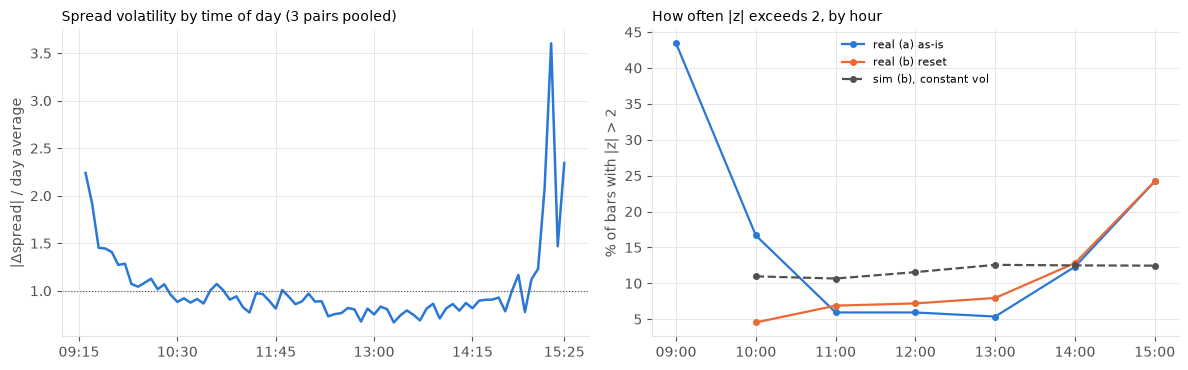

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = prof.index * 5
ax[0].plot(x, prof["pooled"].values, color=C0, lw=1.8)
ax[0].axhline(1, color=br.TEXT_COLOR, lw=0.8, ls=":")
ax[0].set_xticks([0, 75, 150, 225, 300, 370]); ax[0].set_xticklabels(["09:15", "10:30", "11:45", "13:00", "14:15", "15:25"])
ax[0].set_ylabel("|Δspread| / day average")
ax[0].set_title("Spread volatility by time of day (3 pairs pooled)", loc="left", fontsize=10)
hrs = np.arange(len(q6))
for col, c, ls in [("real (a) as-is", C0, "-"), ("real (b) reset", C1, "-"), ("sim (b), constant vol", br.TEXT_COLOR, "--")]:
    ax[1].plot(hrs, q6[col].values * 100, color=c, ls=ls, marker="o", ms=4, label=col)
ax[1].set_xticks(hrs); ax[1].set_xticklabels(q6.index)
ax[1].set_ylabel("% of bars with |z| > 2")
ax[1].set_title("How often |z| exceeds 2, by hour", loc="left", fontsize=10)
ax[1].legend(loc="upper center", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "q6_seasonality.png", dpi=130); plt.show()

**Shape:** a U, steeper at the open. The first 30 minutes run at about 2× midday volatility, the 13:00 hour is the trough (~0.8× the day's average), and volatility climbs again into the close (~1.8× midday in the last 30 minutes). The overnight change is 5–9× a normal 5-minute change.

**Is resetting enough? No.** If z were properly standardized, |z| > 2 would happen equally often at every hour. The simulation shows what a constant-volatility spread gives with these exact windows: a flat ~12% all day for both (a) and (b), so the window mechanics alone explain almost none of the variation. (That ~12% is itself worth noting: a rolling z of a mean-reverting spread is not N(0,1), so "|z| > 2" is not a 5% event.)

The real data under (b) go from 4.5% at 10:00 to 13% at 14:00 and 24% in the 15:00 hour. Midday z is *understated* (the window's std still contains the volatile morning bars), and late-day z is *overstated* (calm midday bars set the std just before the volatility rises into the close). Resetting removes the overnight gap but not the intraday seasonality.

**What a seasonal adjustment would look like:** divide each bar's spread change by that bar-of-day's typical volatility, estimated walk-forward from previous days only, and build the z-score on the cumulated, deseasonalized spread ("volatility time"). That's the natural next ablation; it isn't run here.

## 7. How long does reaching z = 0 take? (Q7)

Treat the standardized spread as an Ornstein-Uhlenbeck process, `dY = −θ Y dt + √(2θ) dW`, with half-life h = ln 2 / θ.

- **Without noise**, E[Y_t] = Y₀ e^(−θt). Going from 2 to 0.5 takes log₂(4) = 2 half-lives, and reaching exactly 0 takes forever.
- **With noise**, the expected first-passage time from z₀ down to z₁ is

  T(z₀ → z₁) = (1/θ) · √(π/2) · ∫ from z₁ to z₀ of e^(u²/2) · erfc(u/√2) du

  (from the backward equation T″ − yT′ = −1/θ with T(z₁) = 0). The Monte Carlo column checks this on a discrete 5-minute grid with h = 46 bars (SBIN/BANKBARODA).

In [17]:
hl = base["SBIN/BANKBARODA"]["hl"]
rows = []
for z0, z1 in [(2, 0), (2, 0.5), (2.5, 0), (3, 0)]:
    sim = ex.simulate_ou_passage(z0, z1, hl)
    rows.append({"from z": z0, "to z": z1, "no noise (half-lives)": ex.deterministic_half_lives(z0, z1),
                 "OU formula (half-lives)": ex.ou_passage_in_half_lives(z0, z1),
                 "Monte Carlo mean": np.nanmean(sim) / hl, "Monte Carlo median": np.nanmedian(sim) / hl,
                 "P(done within 1 half-life)": (sim <= hl).mean(),
                 "P(done within 70 bars = a whole session)": (sim <= 70).mean()})
pd.DataFrame(rows).round(2)

,from z,to z,no noise (half-lives),OU formula (half-lives),Monte Carlo mean,Monte Carlo median,P(done within 1 half-life),P(done within 70 bars = a whole session)
0,2.0,0.0,inf,2.06,2.26,1.81,0.20,0.41
1,2.0,0.5,2.0,1.30,1.44,1.13,0.43,0.65
2,2.5,0.0,inf,2.33,2.54,2.11,0.11,0.31
3,3.0,0.0,inf,2.57,2.77,2.35,0.06,0.23


**About 2 half-lives** from z = 2 to z = 0 (≈95 bars for SBIN/BANKBARODA), against 70 tradeable bars in a whole session. Only ~20% of paths get there within one half-life, and only ~41% within a whole session even when the trade opens at 09:15. The Monte Carlo runs ~10% longer than the formula because a 5-minute grid only sees a crossing at the next bar.

Our real trades revert faster than this (median ~29 bars for the trades that do revert) because the z-score's rolling mean moves toward the spread (section 3). An exit at |z| ≤ 0.5 needs ~1.3 half-lives instead of ~2.1.

In [18]:
rows = []
for p in PAIRS:
    h = base[p]["hl"]
    for name, bkw in {"exit at z = 0 (baseline)": {}, "exit at |z| <= 0.5": dict(exit_threshold=0.5),
                      "z = 0 + time stop at 1 half-life": dict(max_holding_bars=int(round(h)))}.items():
        sig, gr, ne = ex.run_pair(universe[p], {}, bkw)
        row = ex.summarise(gr, ne)
        rows.append({"pair": f"{p} (HL {h:.0f})", "exit rule": name, "Trades": row["Trades"],
                     "Gross return": row["Gross return"], "Net return": row["Net return"],
                     "Gross Sharpe": row["Gross Sharpe"], "Net Sharpe": row["Net Sharpe"],
                     "Exits by reversion": row["Exits by reversion"], "Avg bars held": gr.trades["bars_held"].mean()})
q7 = pd.DataFrame(rows).set_index(["pair", "exit rule"])
q7.style.format({"Gross return": "{:.2%}", "Net return": "{:.2%}", "Gross Sharpe": "{:.2f}", "Net Sharpe": "{:.2f}",
                 "Exits by reversion": "{:.0%}", "Avg bars held": "{:.1f}"})

- **|z| ≤ 0.5** shortens holding periods and raises the reversion share everywhere (e.g. 56% → 71% on SBIN/BANKBARODA). The gross return changes are small and mixed in sign, and none is close to the ~2.4 Sharpe standard error.
- **Time stop at one half-life** is a no-op on HDFCBANK/ICICIBANK and TCS/INFY: their half-lives (133 and 328 bars) are longer than the session, so the 15:05 flatten always comes first. On SBIN/BANKBARODA it cuts some trades that would have reverted later, and does slightly worse.

Neither exit changes the conclusion: costs (~17 bps per round trip) dominate.

## 8. Entry rule: at least k half-lives must remain (Q8)

Rule: enter only if `bars until the 15:05 flatten ≥ k × half-life`, with the half-life from the formation period (known before trading starts). Bars left are counted on the clock, so the rule never peeks at bars that haven't printed yet.

**Choosing k.** Section 7 says the honest k for a z = 0 exit is about 2, but 2 × 46 = 92 bars is more than a whole session (70), so that rule would never trade. **k = 1 is the loosest value the theory supports.** It's also where the section 1 split sits, so it isn't an out-of-sample choice. k = 0.5 and 1.5 are shown only as sensitivity. For an exit at |z| ≤ 0.5 the matching value is k ≈ 1.3 (its OU passage time), shown as a combined rule.

In [19]:
rows = []
for p in PAIRS:
    h = base[p]["hl"]
    cfgs = {"fixed 14:50 cutoff (baseline)": {}, "k = 0.5": dict(min_bars_left=0.5 * h),
            "k = 1 (chosen)": dict(min_bars_left=1.0 * h), "k = 1.5": dict(min_bars_left=1.5 * h),
            "k = 1.3 + exit |z| <= 0.5": dict(min_bars_left=1.3 * h, exit_threshold=0.5)}
    for name, bkw in cfgs.items():
        sig, gr, ne = ex.run_pair(universe[p], {}, bkw)
        row = ex.summarise(gr, ne)
        last = "-" if not row["Trades"] else pd.to_datetime(gr.trades["signal_time"]).dt.strftime("%H:%M").max()
        rows.append({"pair": f"{p} (HL {h:.0f})", "entry rule": name, "Latest entry": last, "Trades": row["Trades"],
                     "Gross return": row["Gross return"], "Net return": row["Net return"],
                     "Gross Sharpe": row.get("Gross Sharpe"), "Net Sharpe": row.get("Net Sharpe"),
                     "Exits by reversion": row.get("Exits by reversion", np.nan)})
q8 = pd.DataFrame(rows).set_index(["pair", "entry rule"])
q8.style.format({"Gross return": "{:.2%}", "Net return": "{:.2%}", "Gross Sharpe": "{:.2f}", "Net Sharpe": "{:.2f}",
                 "Exits by reversion": "{:.0%}"}, na_rep="-")

- **HDFCBANK/ICICIBANK and TCS/INFY:** with half-lives of 133 and 328 bars, k = 1 allows **no trades at all**. That is the right answer: their spreads don't revert on an intraday horizon, so the rule refuses to trade them.
- **SBIN/BANKBARODA, k = 1** (no entries after ~11:15): 38 trades instead of 59, the reversion share rises from 56% to 79%, and net return improves from −3.7% to −2.0%. It is still negative after costs.
- **k = 1.5** looks best (net +0.4%), but on SBIN it allows entries only at 09:15–09:20, so it quietly becomes the overnight-gap trade from section 3. That's a reason *not* to pick it, not a discovery.
- Each Sharpe here carries a standard error of ~2.4, so the gap between two of them is uncertain by ~3.4. The largest gap (k = 1.5's gross Sharpe 3.3 vs 0.26 for the baseline) is about 0.9 of that, and k = 1.5 is ruled out for the reason above. The rule is still the right design (it stops trades that can't finish), but 44 days can't show that it makes money.

## Summary

1. The z = 0 exit plus a fixed 14:50 cutoff opens many trades that can't finish: about 2 half-lives are needed, and a session has ~1.5 (SBIN) or far less (other pairs).
2. Half of all entries are the overnight gap, measured against yesterday's calm afternoon.
3. Resetting the window removes the gap but leaves a U-shaped volatility seasonality that z doesn't account for.
4. Every variant is within one standard error of every other. The robust finding is unchanged: the gross edge per trade is below the ~17 bps round-trip cost.